## Introduction
Representation learning can be used to generate dense, meaningful representations from high-dimensional, unstructured data like images using deep learning. In the following project, dense representations are generated from images using an undercomplete autoencoder network, where a neural network is trained on an image reconstruction task with progressively smaller hidden layers, forcing the network to learn how to recreate the entire image from a 30-dimensional vector. These dense vectors are then compared across images to evaluate their similarity. If the model learns to encode useful, unique features, then images from the same class should have similar embeddings.

First, the necessary dependencies are imported.

In [ ]:
import tensorflow as tf
from tensorflow import keras
import numpy as np
import matplotlib.pyplot as plt

## Data Preparation

Data is loaded from the Fashion-MNIST dataset, which is composed of 70,000  28x28, grayscale images of various pieces of clothing, with the type of clothing labeled as one of ten classes.

In [ ]:
fashion_set = keras.datasets.fashion_mnist
(x_train, y_train), (x_test, y_test) = fashion_set.load_data()
x_train, x_test = x_train/255.0, x_test/255.0

class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
 "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


## Model Architecture and Training

The model architecture is defined and compiled using the Keras Functional API. The model is composed of an encoder-decoder structure where the input passes from a hidden layer of 100 neurons, to a hidden layer of 30 neurons, to another layer of 100 neurons, and then to an output layer matching the input shape, with a reshape layer to convert the flattened vector back to an image. The bottleneck-shaped architecture pushes the model to learn a compressed, dense representation that still allows it to recreate the image as accurately as possible. The 30-neuron hidden layer produces an auxiliary output, which is the image embedding, and is not part of loss calculation.

In [ ]:
input_layer = keras.layers.Input(shape=x_train.shape[1:], name='input_layer')
flatten_layer = keras.layers.Flatten(name='flatten_layer')(input_layer)
hidden1 = keras.layers.Dense(100, activation='relu',name='hidden1')(flatten_layer)
encoder = keras.layers.Dense(30, activation='relu',name='encoder')(hidden1)
dec_hidden1 =  keras.layers.Dense(100, name='dec_hidden1')(encoder)
leakyRelu = keras.layers.LeakyReLU(negative_slope=0.2)(dec_hidden1)
output_flat =  keras.layers.Dense(784, activation='relu',name='output_flat')(leakyRelu)
output_layer = keras.layers.Reshape((28,28),name='output_layer')(output_flat)
model = keras.Model(inputs=[input_layer],
                    outputs={"output_layer": output_layer, "encoder": encoder})
model.summary()

model.compile(optimizer='adam',
          loss={'output_layer' : 'mse',
                'encoder' : None}
)

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 28, 28)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_layer (Flatten)         │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden1 (Dense)                 │ (None, 100)            │        78,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder (Dense)                 │ (None, 30)             │         3,030 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_hidden1 (Dense)             │ (None, 100)            │         3,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_flat (Dense)             │ (None, 784)            │        79,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Reshape)          │ (None, 28, 28)         │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 163,814 (639.90 KB)

 Trainable params: 163,814 (639.90 KB)

 Non-trainable params: 0 (0.00 B)

The model is then trained for 20 epochs, and a batch size of 32.

In [ ]:
model.fit(x_train, {'output_layer' : x_train},
          epochs=20,
          batch_size=32
          )
model.save('autoencoder.keras')

Epoch 1/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 2ms/step - loss: 0.0299
Epoch 2/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 0.0184
Epoch 3/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.0162
Epoch 4/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 0.0154
Epoch 5/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 0.0145
Epoch 6/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.0141
Epoch 7/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 0.0136
Epoch 8/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 0.0134
Epoch 9/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.0133
Epoch 10/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - loss: 0.0131
Epoch 11/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 0.0130
Epoch 12/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 0.0130
Epoch 13/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.0129
Epoch 14/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 0.0129
Epoch 15/20
1875/1875 ━━━━━━

After training, the model is evaluated on unseen data to check for overfitting. Ideally, the loss on the test set should resemble the training set.

In [ ]:
model.evaluate(x_test, {'output_layer' : x_test})

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0128


0.01277133822441101

## Visualizing Image Embeddings

A random sample image from the test set is selected, and the image is plotted alongside the model's reconstruction and a visualization of its embedding vector. The 30-dimensional vector has been reshaped to a 5x6 array for the purpose of visualization, but this is arbitrary, and doesn't represent a positional relationship between parts of the embedding vector and the input image.

sample shape = (1, 28, 28)
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 836ms/step


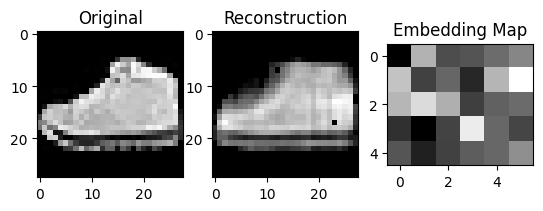

In [ ]:
sample = np.expand_dims(x_test[np.random.randint(1,1000)], axis=0)
print('sample shape =', sample.shape)
pred_dict = model.predict(sample)
pred = pred_dict['output_layer']
encoding = pred_dict['encoder']

plt.subplot(1,3,1)
plt.title('Original')
plt.imshow(sample[0], cmap='gray')

recon = pred[0]
plt.subplot(1,3,2)
plt.title('Reconstruction')
plt.imshow(recon, cmap='gray')

enc_img = encoding.reshape(5,6)
plt.subplot(1,3,3)
plt.title('Embedding Map')
plt.imshow(enc_img, cmap='gray')

plt.show()

### Similarity Matrix
Example embeddings are generated from the test set and cosine similarity between embeddings is plotted on a similarity matrix to examine whether similar items generate similar embeddings.

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 511ms/step


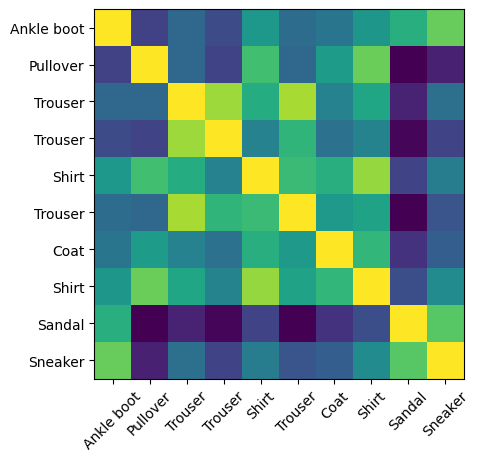

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

sample_embeddings = model.predict(x_test[:10])
sample_classes = y_test[:10]
sample_labels = [class_names[i] for i in sample_classes]

sim_matrix = cosine_similarity(sample_embeddings['encoder'])

fig, ax = plt.subplots()
ax.imshow(sim_matrix)
ticks = [i for i in range(0,10)]
ax.set_xticks(ticks, labels=sample_labels)
ax.set_yticks(ticks, labels=sample_labels)
ax.tick_params(axis='x', labelrotation=45)

After sampling the first ten items from the test set, running the autoencoder to generate embeddings, and comparing their cosine similarity, some patterns become clear, and similar items do seem to create similar embeddings. Sneakers, sandals, and ankle boots have somewhat high similarity to each other while having very low similarity to everything else. Items like shirts, pullover, and coats were also similar, while having less similarity to trousers and less still to sandals or sneakers. Based on these results, the model does seem to learn to generate the most similar embeddings for items in the same class or similar classes.

### t-SNE Visualization
Next, image embeddings are visualized in 2-dimensional space using t-Distributed Stochastic Neighbor Embedding to further visualize how image embeddings cluster together by class.

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 


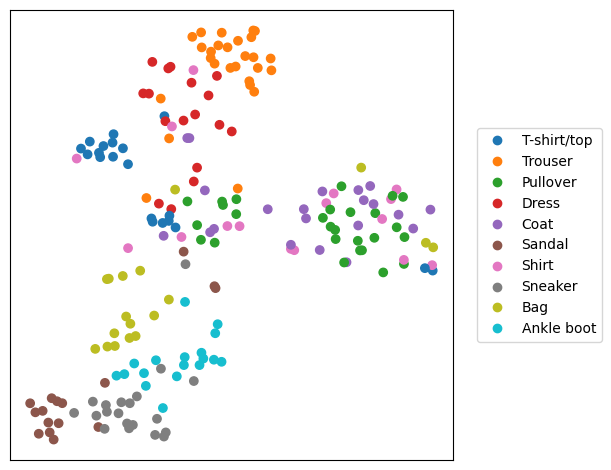

In [ ]:
from sklearn.manifold import TSNE

tsne_samples = model.predict(x_test[:200])
tsne_array = TSNE(n_components=2).fit_transform(tsne_samples['encoder'])

scatter_plot = plt.scatter(tsne_array[:,0], tsne_array[:,1], c=y_test[:200], cmap='tab10')
handles, labels = scatter_plot.legend_elements()
plt.legend(handles, class_names, loc='center right', bbox_to_anchor=(1.35,0.5))
plt.xticks([])
plt.yticks([])
plt.tight_layout()
plt.show()

Observing the clusters, it seems like pullovers, coats, and shirts heavily overlap within their clusters, while classes like sneakers, sandals, or bags are more neatly separated.

### Vector Arithmetic

The embedding space also allows for vector arithmetic, where the encoding vector for one image can be added to or subtracted from another and decoded to examine how it affects the image. To do this, a decoder model is created by copying the layers and weights of the decoder half of the autoencoder model. This model will take vector embeddings as input and output the decoded image.

In [ ]:
decoder = keras.models.Sequential()

decoder.add(keras.layers.Input(shape=(30,)))
for layer in model.layers[4:]:
  decoder.add(layer)

decoder.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dec_hidden1 (Dense)             │ (None, 100)            │         3,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_flat (Dense)             │ (None, 784)            │        79,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Reshape)          │ (None, 28, 28)         │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 82,284 (321.42 KB)

 Trainable params: 82,284 (321.42 KB)

 Non-trainable params: 0 (0.00 B)

Two samples are chosen, an image of a shirt and an image of trousers. The embedding vector for the trousers is added to the embedding from the shirt to create a new image.

Text(0.5, 1.0, 'Shirt + Trousers')

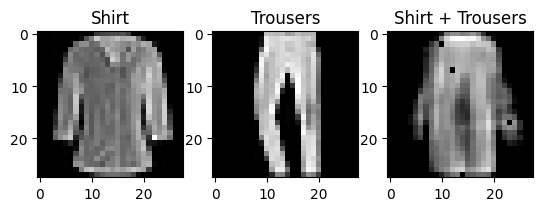

In [ ]:
shirt_sample = x_test[4]
trouser_sample = x_test[5]

math_vecs = model(np.array([shirt_sample, trouser_sample]))['encoder']
shirt_vec = math_vecs[0]
trousers_vec = math_vecs[1]
sum_vec = shirt_vec + trousers_vec

sum_image = decoder(sum_vec[None,:])

fig, ax = plt.subplots(1,3)
ax[0].imshow(shirt_sample, cmap='grey')
ax[0].set_title('Shirt')
ax[1].imshow(trouser_sample, cmap='grey')
ax[1].set_title('Trousers')
ax[2].imshow(sum_image[0], cmap='grey')
ax[2].set_title('Shirt + Trousers')

## Conclusion
While we were able to generate image embeddings for items in the dataset, visualize them, and perform some basic vector arithmetic, the model and approach have a number of limitations that could be addressed with changes to architecture or methodology. Possible changes could include:
- Introducing masked portions or random noise to the input image to push the model to learn to recreate the full image with limited information, raising the chance that the model learns truly useful features rather than memorizing its training set.
- A more varied dataset, as the current training and testing set contain highly consistent, generic images. This may be allowing the model to perform well on the test set even after overfitting the training set.
- Training validation and callbacks. This would help to prevent overfitting.
- A convolutional neural network architecture instead of a fully-connected network. CNNs generally perform better on image-related tasks, and are more capable of learning distinct visual features.